# QUTCC Notebooks

This notebook walks through two demos of QUTCC's uncertainty quantification, each self-contained.

**Part 1** reproduces our Gaussian toy example: we compare QUTCC against a Deep Ensemble
and MC-Dropout on a synthetic problem with a known, closed-form posterior, so we can
see exactly how close each method's uncertainty estimate gets to the truth. All three
models are pretrained -- the notebook downloads the checkpoints from Google Drive for
you, so there's no training to wait on.

**Part 2**: Loads a QUTCC quantile model trained on real microscopy
data and see what it actually produces -- a denoised reconstruction, a pixel-by-pixel
uncertainty map, and the full predictive distribution at any pixel you pick.


In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# REPO_DIR = the root of your QUTCC clone (the folder containing "models/", "notebooks/", etc.).
# Auto-detected below for the two common cases:
#   - Jupyter's working directory is already the repo root -> use it as-is.
#   - Jupyter's working directory is notebooks/ (the usual default) -> go up one level.
# If neither guess is right (e.g. a custom Colab path like
# "/content/drive/MyDrive/QUTCC"), set REPO_DIR manually instead:
#   REPO_DIR = Path("/content/drive/MyDrive/QUTCC")
REPO_DIR = Path(".").resolve()
if not (REPO_DIR / "models").exists():
    REPO_DIR = Path("..").resolve()

assert (REPO_DIR / "models" / "checkpointing.py").exists(), (
    f"Couldn't find the QUTCC repo at {REPO_DIR} -- set REPO_DIR manually above."
)
sys.path.insert(0, str(REPO_DIR))
sys.path.insert(0, str(REPO_DIR / "notebooks"))  # for toy_problem.py

# Several repo modules (e.g. models/checkpointing.py's create_model) load files
# via paths relative to the repo root (e.g. "models/model_config.yaml"), so the
# working directory has to be REPO_DIR too, not wherever this notebook file lives.
os.chdir(REPO_DIR)
print(f"Using repo at: {REPO_DIR}")

Using repo at: /home/ty392/UQNet/QUTCC


# Part 1: Gaussian Toy Example -- QUTCC vs. Deep Ensemble vs. MC-Dropout

Reproduces the paper's toy-problem figure comparing three uncertainty
quantification methods against a **closed-form posterior**: a synthetic
linear-Gaussian inverse problem built from an MNIST digit, where the true
per-pixel posterior mean/std are known analytically (no neural network
approximation needed for ground truth).

- **QUTCC**: a quantile-regression U-Net queried at `K` quantile levels; the
  per-pixel PDF is recovered from the derivative of the learned quantile
  function (same `QUTCC_eval` math used in Part 2 below).
- **Deep Ensemble**: `M` independently-trained U-Nets, each predicting a
  per-pixel mean and variance via a Gaussian NLL loss; combined via the law
  of total expectation/variance.
- **MC-Dropout**: a single U-Net with dropout inserted throughout
  (`models/dropout.py`), with dropout left active at inference to draw `S`
  stochastic samples per pixel.

All three share the same U-Net backbone so size and complexity are matched;
only the output head and dropout differ. The toy-problem setup, checkpoint
downloading/loading, and inference/PDF-recovery utilities all live in
`notebooks/toy_problem.py` -- this notebook just calls into them.

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt

import toy_problem as tp

plt.rcParams["figure.facecolor"] = "white"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


## Build the toy inverse problem

A linear-Gaussian measurement of an MNIST digit, with a closed-form Gaussian posterior -- the "ground truth" we compare all three methods against.

Ground truth digit label: 3


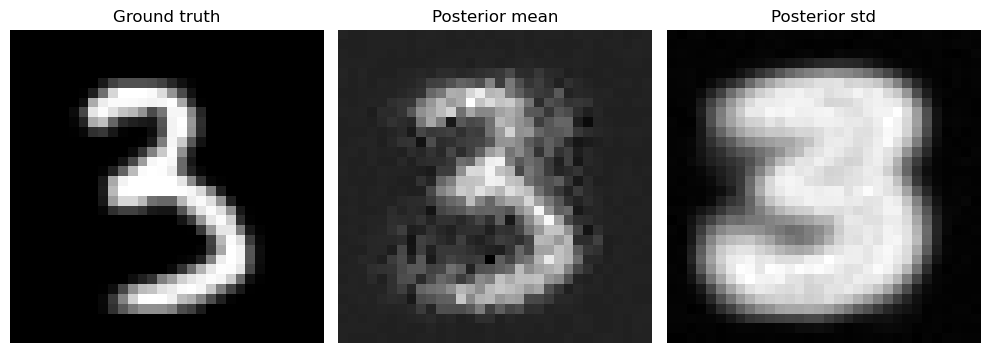

In [3]:
data_root = str(REPO_DIR / "data" / "mnist")
problem = tp.build_toy_problem(data_root, tp.SEED)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(problem["gt"], cmap="gray"); axes[0].set_title("Ground truth"); axes[0].axis("off")
axes[1].imshow(problem["mean_pos"], cmap="gray"); axes[1].set_title("Posterior mean"); axes[1].axis("off")
axes[2].imshow(problem["sigma_pos"], cmap="gray"); axes[2].set_title("Posterior std"); axes[2].axis("off")
plt.tight_layout()
plt.show()

## Load the three pretrained models

Downloads `quantile.pth`, `mc_dropout.pth`, and `ensemble.pth` from Google Drive
into `CHECKPOINT_DIR` if they aren't already there, then loads all three.

In [4]:
tp.download_pretrained_checkpoints(tp.DEFAULT_CHECKPOINT_DIR)
quantile_model, mc_model, ensemble_members = tp.load_pretrained_models(tp.DEFAULT_CHECKPOINT_DIR, DEVICE)

All checkpoints already present in /home/ty392/UQNet/QUTCC/notebooks/toy_checkpoints.
[quantile] parameters: 20,703,617
[mc_dropout] parameters: 20,703,617
[ensemble] parameters per member: 20,704,770


## Run inference on the test measurement

Query each model on the single noisy measurement built above.

In [5]:
x_adj_test = (problem["obs"].to(DEVICE) @ problem["A"].to(DEVICE)).view(1, 1, tp.N, tp.N)
levels = np.linspace(0.01, 0.99, tp.K).astype(np.float32)

qf = tp.get_quantile_functions(quantile_model, x_adj_test, levels, DEVICE)
mc_mean, mc_var = tp.get_mc_dropout_moments(mc_model, x_adj_test, DEVICE)
ens_mean, ens_var = tp.get_ensemble_moments(ensemble_members, x_adj_test, DEVICE)

mean_pos_np = problem["mean_pos"].detach().cpu().numpy()
sigma_pos_np = problem["sigma_pos"].detach().cpu().numpy()

[quantile] crossings before isotonic regression: 0
[quantile] crossings after  isotonic regression: 0


## Reproduce the figure

Left block: posterior mean/std maps for the true posterior and all three methods,
with two marked pixels (green = low uncertainty, cyan = high uncertainty, both
inside the digit). Right block: per-pixel density overlays at those two pixels.

In [6]:
figure_data = tp.prepare_figure_data(
    qf, levels, mc_mean, mc_var, ens_mean, ens_var, mean_pos_np, sigma_pos_np)

Integrating QUTCC pdfs to get mean/std maps (this loops over all pixels)...
Computing QUTCC KL-divergence map to pick well-matched pixels...
green pixel: (17, 12)  mean=0.3957  sigma=0.1297
cyan  pixel: (22, 5)  mean=-0.0225  sigma=0.1156


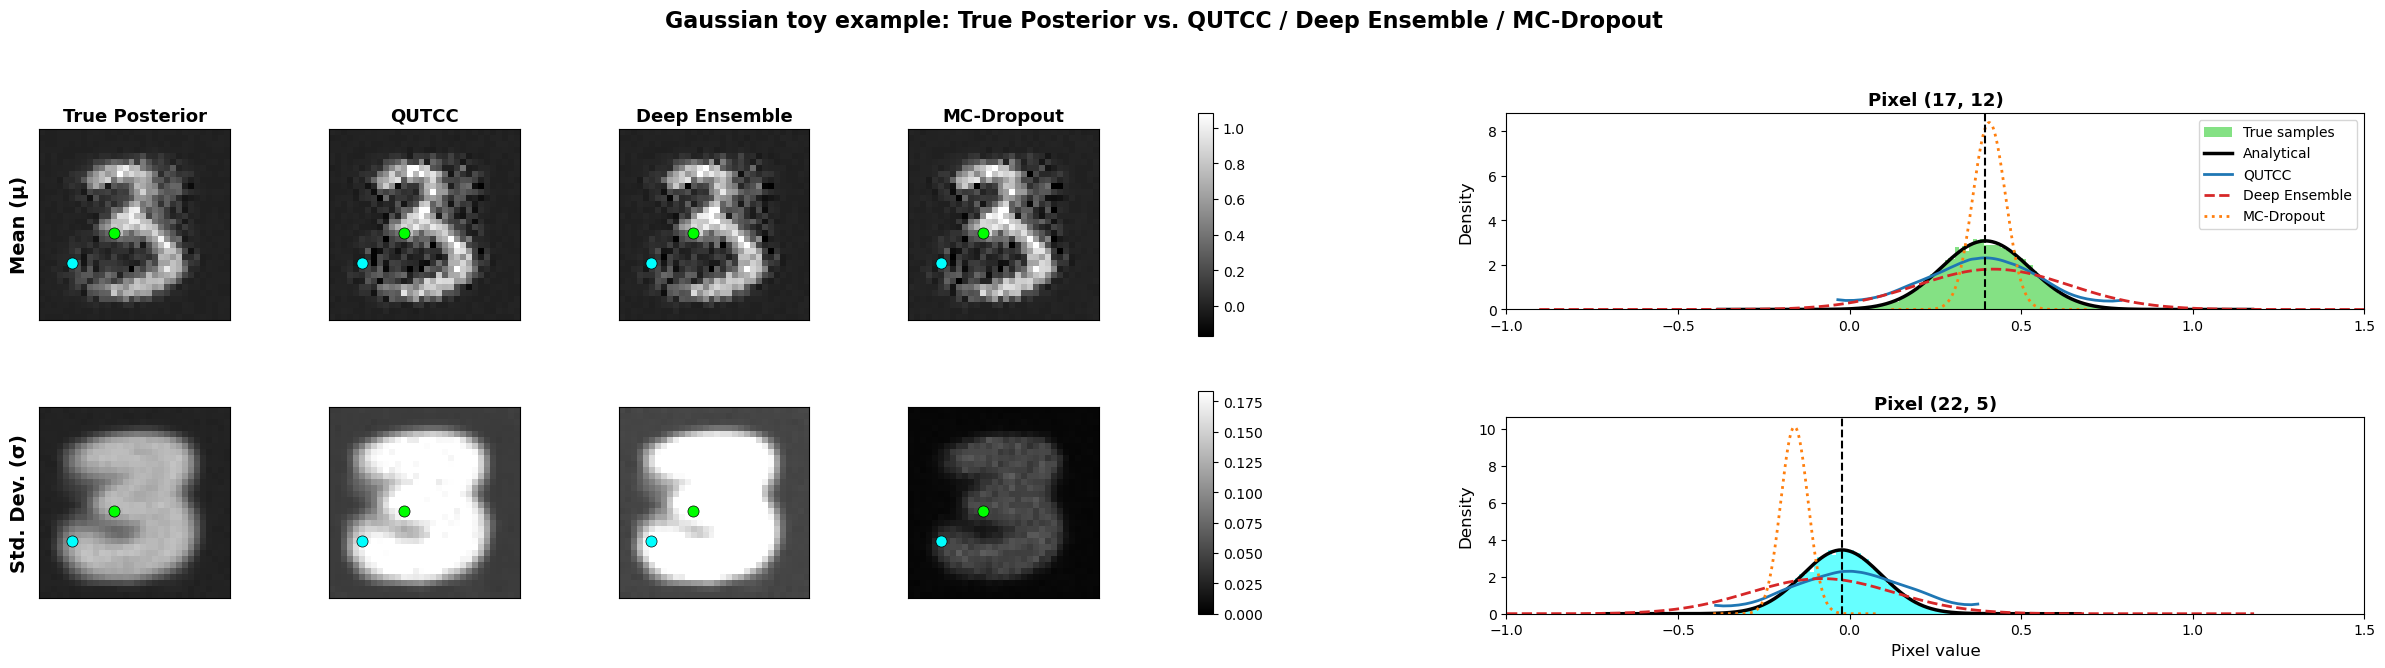

In [7]:
tp.plot_comparison_figure(
    qf, levels, mean_pos_np, sigma_pos_np, mc_mean, mc_var, ens_mean, ens_var, figure_data)

# Part 2: QUTCC Checkpoint Explorer -- Gaussian-noise FMD

Load a trained QUTCC quantile model (`unet_quantile`) and run it on a Gaussian-noise
sample from the FMD denoising dataset to see:

- **Mean** of the predictive distribution (expectation of the learned quantile function)
- **Reconstruction** (median prediction, q = 0.5)
- **UQ map** (predicted interval width, a per-pixel uncertainty heatmap)

and then zoom into a single pixel's full **conditional predictive PDF**.

In [8]:
import random

from models.checkpointing import create_model, load_model_state
from datasets.fmd.data_loader import load_noisy_single_loader
from QUTCC_eval import get_quantile_outputs, extract_sorted_pdf, plot_pdf

## Config

`CHECKPOINT_PATH` and `FMD_IMAGE_DIR` are fixed below and auto-downloaded from Google Drive if missing (see the next cell) -- nothing to edit there. The rest (noise level, which sample to look at, UQ bounds) are free to tune.

In [9]:
# --- Pretrained checkpoint + sample FMD image, hosted on Google Drive ---
GDRIVE_PART2_URL = "https://drive.google.com/drive/folders/1YbjpZ_yL9s57Jg5UFsv4bwkIZ-q1zLiA?usp=sharing"
PART2_DIR = str(REPO_DIR / "notebooks" / "part2_checkpoint")  # downloaded into here if missing
CHECKPOINT_PATH = os.path.join(PART2_DIR, "model_weight.pth")  # a trained unet_quantile checkpoint
FMD_IMAGE_DIR = PART2_DIR                                      # folder of clean FMD images (just the one sample here)

IN_CHANNELS = 1
NOISE_SIGMA = 0.3   # synthetic Gaussian noise std added to the clean FMD image;
                    # keep this within the range the checkpoint was trained on
                    # (see training/gaussian_quantile_train.sh, e.g. sigma in [0, 0.5])
SAMPLE_INDEX = 0    # which image in FMD_IMAGE_DIR to visualize

# Uncalibrated default UQ bounds (see models/checkpointing.py); after running
# calibration_sweep.py for this checkpoint, swap these for the calibrated
# lower_q/upper_q it found for a true conformal interval.
LOWER_Q = 0.05
UPPER_Q = 0.95

## Download (if needed) and load the checkpoint

Downloads `epoch20.pth` and the sample FMD image from Google Drive into `PART2_DIR` if they're not already there, then loads the model.

In [10]:
if not os.path.exists(CHECKPOINT_PATH):
    import gdown
    print(f"Checkpoint not found at {CHECKPOINT_PATH} -- downloading from Google Drive...")
    gdown.download_folder(url=GDRIVE_PART2_URL, output=PART2_DIR, quiet=False, use_cookies=False)

model = create_model(net="unet_quantile", device=DEVICE, in_channels=IN_CHANNELS)
model = load_model_state(model, CHECKPOINT_PATH, DEVICE)
model.eval()
print("Model loaded.")

Model state loaded from /home/ty392/UQNet/QUTCC/notebooks/part2_checkpoint/model_weight.pth
Model loaded.


## Load a Gaussian-noise FMD sample

In [11]:
random.seed(0)
torch.manual_seed(0)

# Fixing min_noise == max_noise with num_noise=1 gives every image the same, fixed sigma.
loader = load_noisy_single_loader(
    noise_type="gaussian", min_noise=NOISE_SIGMA, max_noise=NOISE_SIGMA, num_noise=1,
    image_folder=FMD_IMAGE_DIR, batch_size=1,
)
noisy, clean = loader.dataset[SAMPLE_INDEX]
noisy, clean = noisy.unsqueeze(0).to(DEVICE), clean.unsqueeze(0).to(DEVICE)
print(f"noisy: {noisy.shape}, clean: {clean.shape}")

noisy: torch.Size([1, 1, 512, 512]), clean: torch.Size([1, 1, 512, 512])


## Run inference: Mean, Reconstruction, UQ map

In [12]:
def predict_quantile(x: torch.Tensor, q: float) -> torch.Tensor:
    q_tensor = torch.full((x.shape[0],), q, device=DEVICE, dtype=torch.float32)
    with torch.no_grad():
        return model(x, q_tensor)

median_pred = predict_quantile(noisy, 0.5)             # point reconstruction
lower_pred  = predict_quantile(noisy, LOWER_Q)
upper_pred  = predict_quantile(noisy, UPPER_Q)
uq_map = (upper_pred - lower_pred).clamp(min=0)          # interval width, per pixel

# Mean of the predictive distribution: E[X] = integral_0^1 Q(p) dp, estimated from a
# dense sweep of the learned quantile function Q (this can differ from the median
# whenever the per-pixel predictive distribution is skewed/asymmetric).
fmd_quantile_levels = np.linspace(0.02, 0.98, 25)
fmd_quantile_preds, fmd_pdf_est = get_quantile_outputs(model, noisy, fmd_quantile_levels, DEVICE)
mean_pred = np.trapz(fmd_quantile_preds, fmd_quantile_levels, axis=0)

print(f"Mean UQ width: {uq_map.mean().item():.4f}")

Mean UQ width: 0.0542


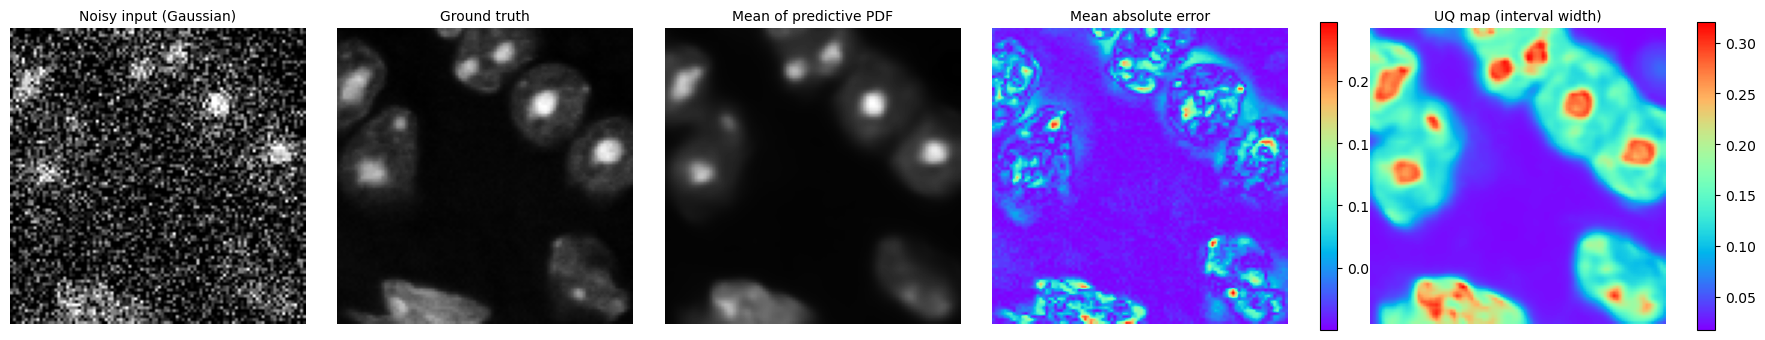

In [13]:
def show(ax, img, title, cmap="gray", vmax=None):
    im = ax.imshow(img, cmap=cmap, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    return im


# --- Zoom into a 100x100 crop (top-left corner below; edit to look elsewhere) ---
CROP_ROW, CROP_COL, CROP_SIZE = 360, 260, 100
crop = (slice(CROP_ROW, CROP_ROW + CROP_SIZE), slice(CROP_COL, CROP_COL + CROP_SIZE))

clean_np = clean[0, 0].cpu().numpy()
mae_map = np.abs(mean_pred - clean_np)

# Dedicated narrow columns for the two colorbars, so they don't shrink the image
# panels they're attached to -- all 5 image panels stay the same size.
fig = plt.figure(figsize=(22, 4))
gs = fig.add_gridspec(1, 7, width_ratios=[1, 1, 1, 1, 0.06, 1, 0.06], wspace=0.15)

show(fig.add_subplot(gs[0, 0]), noisy[0, 0].cpu().numpy()[crop], "Noisy input (Gaussian)")
show(fig.add_subplot(gs[0, 1]), clean_np[crop], "Ground truth")
show(fig.add_subplot(gs[0, 2]), mean_pred[crop], "Mean of predictive PDF")

im_mae = show(fig.add_subplot(gs[0, 3]), mae_map[crop], "Mean absolute error", cmap="rainbow")
fig.colorbar(im_mae, cax=fig.add_subplot(gs[0, 4]))

im_uq = show(fig.add_subplot(gs[0, 5]), uq_map[0, 0].cpu().numpy()[crop], "UQ map (interval width)", cmap="rainbow")
fig.colorbar(im_uq, cax=fig.add_subplot(gs[0, 6]))

plt.show()

## Conditional distribution at a pixel

Set `ROW, COL` below to any pixel in the image to see the model's full conditional
predictive PDF there, derived from the derivative of the learned quantile function.
The left panel shows the same crop as above with a star marking that pixel
(defaults to the brightest pixel in the crop).

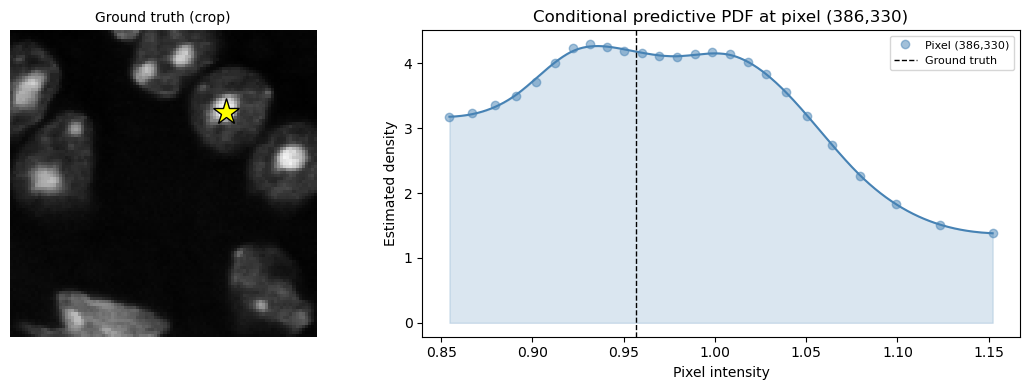

In [14]:
ROW, COL = 386, 330   # <-- pick a pixel coordinate (0-indexed; must be within the image H x W)

s, p = extract_sorted_pdf(fmd_quantile_preds, fmd_pdf_est, ROW, COL)

fig, (ax_crop, ax_pdf) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.4]})

ax_crop.imshow(clean_np[crop], cmap="gray")
ax_crop.set_title("Ground truth (crop)", fontsize=10)
ax_crop.axis("off")
# Star position is relative to the crop -- only lands on-image if (ROW, COL) falls inside it.
ax_crop.plot(COL - CROP_COL, ROW - CROP_ROW, marker="*", color="yellow",
             markersize=20, markeredgecolor="black", markeredgewidth=1)

plot_pdf(ax_pdf, s, p, color="steelblue", label=f"Pixel ({ROW},{COL})")
ax_pdf.axvline(clean[0, 0, ROW, COL].item(), color="black", ls="--", lw=1, label="Ground truth")
ax_pdf.set_xlabel("Pixel intensity")
ax_pdf.set_ylabel("Estimated density")
ax_pdf.set_title(f"Conditional predictive PDF at pixel ({ROW},{COL})")
ax_pdf.legend(fontsize=8)
fig.tight_layout()
plt.show()